# KI-Labor – Assignment 4: Transfer Learning

**Datensatz:** FGVC-Aircraft (`torchvision.datasets.FGVCAircraft`): Flugzeugbilder, Klassifikation auf Ebene der **Variante** (100 Klassen, z. B. `737-300` vs. `737-400`). Das ist eine *fine-grained*-Aufgabe mit wenigen Bildern pro Klasse und deshalb ein guter Testfall für Transfer Learning.

**Vergleich:**

| Ansatz | Strategie |
|---|---|
| Custom CNN mit BatchNorm | von Grund auf trainiert (Baseline) |
| ResNet18 (ImageNet) | Fixed Feature Extractor / Fine-Tuning |
| EfficientNet_B5 (ImageNet) | Fixed Feature Extractor / Fine-Tuning |

**Für alle Ansätze gleich:** derselbe offizielle Split (train → Training, val → Monitoring je Epoche, test → finale Bewertung, nur einmal pro Modell), dieselbe Metrik (Top-1-Accuracy), dieselbe Hardware, dieselbe Trainingsschleife (bf16-Autocast) und dieselbe Zeitmessung (alle Epochen inkl. Validierung, ohne Laden der Daten und Testen).

In [1]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.tensorboard import SummaryWriter

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps") # Für Macs
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print(f"PyTorch {torch.__version__} | GPU-Gerät: {DEVICE}")

I0000 00:00:1793229982.710381  194990 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793229983.006446  194990 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793229984.335601  194990 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


PyTorch 2.14.1+cu130 | GPU-Gerät: cuda


## 1. Datensatz laden und ansehen

Für das Custom CNN werden die Bilder auf 64×64 px verkleinert. Die vortrainierten Modelle bekommen später ihre eigene Vorverarbeitung (`weights.transforms()`). Für das Training gibt es bei allen Ansätzen als einzige Augmentation ein horizontales Spiegeln.

In [2]:
IMG_SIZE = 64
batch_size = 32

# Augmentation nur fürs Training (Flugzeuge bleiben gespiegelt dieselbe Klasse)
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

trainset = torchvision.datasets.FGVCAircraft(root="./data", split="train", download=True, transform=train_transform)
valset = torchvision.datasets.FGVCAircraft(root="./data", split="val", download=True, transform=transform)
testset = torchvision.datasets.FGVCAircraft(root="./data", split="test", download=True, transform=transform)

classes = trainset.classes
NUM_WORKERS = 8

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)
valloader = torch.utils.data.DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)

print(f"Train: {len(trainset)} | Val: {len(valset)} | Test: {len(testset)} Bilder")

Train: 3334 | Val: 3333 | Test: 3333 Bilder


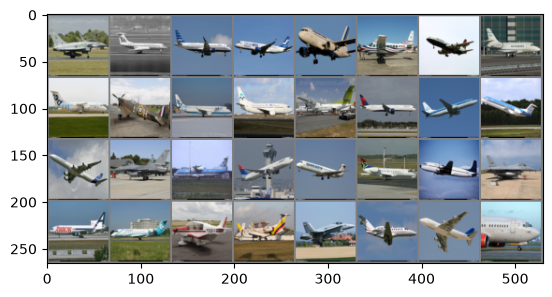

Eurofighter Typhoon Tu-134 E-190 E-190 A319  Cessna 208 L-1011 Falcon 2000 BAE 146-300 Spitfire E-195 737-500 DHC-8-300 757-300 737-900 Fokker 100 A340-600 F-16A/B ATR-72 767-400 MD-80 ERJ 135 DC-6  F-16A/B L-1011 CRJ-200 DR-400 Embraer Legacy 600 F/A-18 Cessna 525 747-200 737-600


In [3]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image


def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

In [4]:
from collections import Counter
from PIL import Image

raw_train = torchvision.datasets.FGVCAircraft(root="./data", split="train", download=True)

# Anzahl Klassen
num_classes = len(raw_train.classes)

# Input-Kanäle
img, label = raw_train[0]
modes = Counter(Image.open(f).mode for f in raw_train._image_files)
in_channels = len(img.getbands())          # RGB -> 3

# Bildgrößen (variieren!)
sizes = [Image.open(f).size for f in raw_train._image_files]   # liest nur den Header, schnell
widths, heights = zip(*sizes)

# Klassenverteilung (wichtig für die Wahl der Metrik)
counts = Counter(raw_train._labels)

print(f"Klassen: {num_classes}  (z.B. {raw_train.classes[:3]})")
print(f"Kanäle: {in_channels}  Modi: {dict(modes)}")
print(f"Breite: {min(widths)}–{max(widths)} px, Höhe: {min(heights)}–{max(heights)} px, "
      f"{len(set(sizes))} verschiedene Größen")
print(f"Bilder pro Klasse: {min(counts.values())}–{max(counts.values())}")

# Form nach dem Transform, also das, was das Netz tatsächlich bekommt
x, _ = trainset[0]
print(f"Tensor-Shape fürs Netz: {tuple(x.shape)}")   # (3, 32, 32)


Klassen: 100  (z.B. ['707-320', '727-200', '737-200'])
Kanäle: 3  Modi: {'RGB': 3334}
Breite: 775–1600 px, Höhe: 430–1188 px, 649 verschiedene Größen
Bilder pro Klasse: 33–34
Tensor-Shape fürs Netz: (3, 64, 64)


**Ergebnis der Analyse:**

- **Größe:** 3334 Trainings-, 3333 Validierungs- und 3333 Testbilder (offizieller Split, keine Überschneidung)
- **Klassen:** 100 Flugzeugvarianten
- **Input-Kanäle:** 3 (alle Bilder sind RGB)
- **Bildgrößen:** sehr unterschiedlich (ca. 775–1600 × 430–1188 px), deshalb wird für jedes Modell auf eine feste Größe skaliert (CNN: 64×64, ResNet18: 224×224, EfficientNet_B5: 456×456)
- **Metrik:** Mit 33–34 Bildern pro Klasse sind die Klassen praktisch **balanciert**. Die **Top-1-Accuracy** auf dem Test-Split ist daher aussagekräftig und wird für alle Ansätze verwendet. Zufallsniveau: 1 %.

## 2. Custom CNN von Grund auf (Baseline)

Aufbau wie in Woche 3, aber mit `BatchNorm2d` nach jeder Faltung: 4× Conv-BN-ReLU, 2× MaxPool, danach 2 Fully-Connected-Schichten mit Dropout. Training mit SGD (lr 0.01, Momentum 0.9, Weight Decay 5e-4) über 20 Epochen.

In [5]:
class BNNet(nn.Module):
    def __init__(self, in_channels, num_classes, img_size):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 32, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 128, 3, padding=1, bias=False)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(128 * (img_size // 4) ** 2, 512)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = torch.flatten(x, 1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)


In [6]:
# bf16-Autocast für alle Modelle gleich (sonst passt EfficientNet_B5 bei 456 px nicht in den GPU-Speicher)
USE_AMP = DEVICE.type == "cuda"


def count_trainable(net):
    return sum(p.numel() for p in net.parameters() if p.requires_grad)


def evaluate(net, loader, criterion):
    net.eval()   # wichtig: BatchNorm nutzt dann die gelernten Statistiken
    loss_sum = correct = total = 0
    with torch.no_grad(), torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=USE_AMP):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = net(images)
            loss_sum += criterion(outputs.float(), labels).item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total


def train(net, writer, epochs=20, lr=0.01, optimizer=None, train_loader=None, val_loader=None, frozen_head=None):
    """Gemeinsame Trainingsschleife für alle Ansätze.

    frozen_head: beim Feature-Extractor der neue Klassifikationskopf. Der Rest des Netzes bleibt
    dann im eval-Modus, damit BatchNorm die ImageNet-Statistiken nicht überschreibt.
    """
    train_loader = train_loader or trainloader
    val_loader = val_loader or valloader
    net.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    if optimizer is None:
        optimizer = optim.SGD(net.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.perf_counter()
    for epoch in range(epochs):
        if frozen_head is None:
            net.train()
        else:
            net.eval()
            frozen_head.train()
        loss_sum = correct = total = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            with torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=USE_AMP):
                outputs = net(inputs)
                loss = criterion(outputs.float(), labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        val_loss, val_acc = evaluate(net, val_loader, criterion)
        for key, value in zip(history, (loss_sum / total, correct / total, val_loss, val_acc)):
            history[key].append(value)
            writer.add_scalar(key, value, epoch)
        print(f"[{epoch + 1:2d}] train loss {loss_sum / total:.3f} acc {100 * correct / total:5.1f} % | "
              f"val loss {val_loss:.3f} acc {100 * val_acc:5.1f} %")
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    duration = time.perf_counter() - start
    writer.flush()
    print(f"Finished Training on {DEVICE} in {duration:.1f} s")
    return history, duration


def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(history["train_loss"], label="train"); ax1.plot(history["val_loss"], label="val")
    ax1.set(title=f"{title} – Loss", xlabel="Epoche"); ax1.legend()
    ax2.plot(history["train_acc"], label="train"); ax2.plot(history["val_acc"], label="val")
    ax2.set(title=f"{title} – Accuracy", xlabel="Epoche"); ax2.legend()
    plt.show()


results = []   # eine Zeile pro Ansatz für die Vergleichstabelle

[ 1] train loss 4.673 acc   1.2 % | val loss 4.577 acc   1.7 %


[ 2] train loss 4.584 acc   1.4 % | val loss 4.579 acc   1.9 %


[ 3] train loss 4.575 acc   1.9 % | val loss 4.540 acc   2.1 %


[ 4] train loss 4.558 acc   1.9 % | val loss 4.527 acc   2.2 %


[ 5] train loss 4.539 acc   2.0 % | val loss 4.530 acc   2.5 %


...

[17] train loss 4.262 acc   5.8 % | val loss 4.299 acc   6.0 %


[18] train loss 4.219 acc   6.2 % | val loss 4.236 acc   6.0 %


[19] train loss 4.201 acc   5.7 % | val loss 4.195 acc   7.6 %


[20] train loss 4.135 acc   7.0 % | val loss 4.152 acc   7.7 %
Finished Training on cuda in 274.7 s


Test-Accuracy: 7.32 %  |  Trainingszeit: 274.7 s


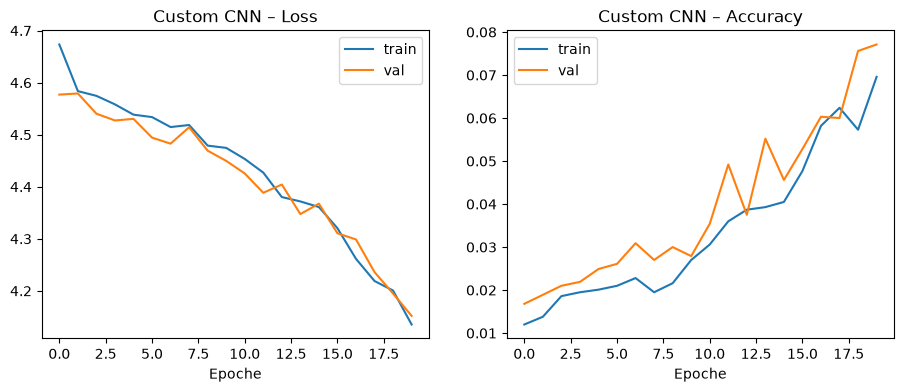

In [7]:
torch.manual_seed(SEED)
net = BNNet(in_channels, num_classes, IMG_SIZE)

writer = SummaryWriter("runs/fgvc/bnnet")
history, train_time = train(net, writer)
writer.close()

test_loss, test_acc = evaluate(net, testloader, nn.CrossEntropyLoss())
print(f"Test-Accuracy: {100 * test_acc:.2f} %  |  Trainingszeit: {train_time:.1f} s")
results.append({"Modell": "Custom CNN (BNNet)", "Strategie": "from scratch", "Auflösung": f"{IMG_SIZE} px",
                "Epochen": len(history["val_acc"]), "Trainierbare Parameter": count_trainable(net),
                "Trainingszeit [s]": round(train_time, 1), "Test-Accuracy [%]": round(100 * test_acc, 2)})

plot_history(history, "Custom CNN")
del net
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

## 3. Transfer Learning: ResNet18 und EfficientNet_B5

Beide Netze werden mit ImageNet-Gewichten geladen. Der ImageNet-Kopf mit 1000 Ausgängen wird durch eine neue `Linear`-Schicht mit 100 Ausgängen ersetzt.

- **Fixed Feature Extractor:** `requires_grad=False` für alle vortrainierten Gewichte. Trainiert wird nur der neue Kopf (Adam, lr 1e-3, 15 Epochen). Das Backbone bleibt im `eval`-Modus, damit BatchNorm die ImageNet-Statistiken behält.
- **Fine-Tuning:** Alle Gewichte werden trainiert, mit **differenzierten Lernraten**: Backbone lr 1e-4 (die vortrainierten Features sollen nur leicht angepasst werden), neuer Kopf lr 1e-3 (startet zufällig). Adam, 10 Epochen.

Als Vorverarbeitung dient jeweils `weights.transforms()` (Resize/Crop, ImageNet-Normalisierung). Wegen der 456-px-Eingaben braucht EfficientNet_B5 viel Speicher, daher Batchgröße 16 statt 32.

In [8]:
from torchvision.models import EfficientNet_B5_Weights, ResNet18_Weights, efficientnet_b5, resnet18

ARCHS = {
    "ResNet18": (resnet18, ResNet18_Weights.DEFAULT),
    "EfficientNet_B5": (efficientnet_b5, EfficientNet_B5_Weights.DEFAULT),
}


def make_loaders(weights, batch_size):
    preprocess = weights.transforms()   # Resize, Crop, ToTensor, ImageNet-Normalisierung
    train_tf = transforms.Compose([transforms.RandomHorizontalFlip(), preprocess])
    splits = {
        "train": torchvision.datasets.FGVCAircraft(root="./data", split="train", transform=train_tf),
        "val": torchvision.datasets.FGVCAircraft(root="./data", split="val", transform=preprocess),
        "test": torchvision.datasets.FGVCAircraft(root="./data", split="test", transform=preprocess),
    }
    return {name: torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=(name == "train"),
                                              num_workers=NUM_WORKERS, pin_memory=True)
            for name, ds in splits.items()}


def build_transfer_model(arch, strategy):
    constructor, weights = ARCHS[arch]
    net = constructor(weights=weights)
    if strategy == "frozen":
        for parameter in net.parameters():
            parameter.requires_grad = False
    # neuen Kopf erst nach dem Einfrieren einsetzen -> nur er ist trainierbar
    if arch == "ResNet18":
        net.fc = nn.Linear(net.fc.in_features, num_classes)
        head = net.fc
    else:
        net.classifier[1] = nn.Linear(net.classifier[1].in_features, num_classes)
        head = net.classifier   # Dropout + Linear
    return net.to(DEVICE), head


def run_transfer(arch, strategy, epochs, lr_head, lr_backbone=None, batch_size=32):
    torch.manual_seed(SEED)
    weights = ARCHS[arch][1]
    loaders = make_loaders(weights, batch_size)
    net, head = build_transfer_model(arch, strategy)

    if strategy == "frozen":
        optimizer = optim.Adam(head.parameters(), lr=lr_head)
    else:
        head_params = set(head.parameters())
        backbone_params = [p for p in net.parameters() if p not in head_params]
        optimizer = optim.Adam([{"params": backbone_params, "lr": lr_backbone},
                                {"params": head.parameters(), "lr": lr_head}])

    trainable = count_trainable(net)
    print(f"{arch} ({strategy}): {trainable:,} von {sum(p.numel() for p in net.parameters()):,} Parametern trainierbar")

    writer = SummaryWriter(f"runs/fgvc/{arch.lower()}_{strategy}")
    history, train_time = train(net, writer, epochs, optimizer=optimizer,
                                train_loader=loaders["train"], val_loader=loaders["val"],
                                frozen_head=head if strategy == "frozen" else None)
    writer.close()

    _, test_acc = evaluate(net, loaders["test"], nn.CrossEntropyLoss())
    print(f"Test-Accuracy: {100 * test_acc:.2f} %  |  Trainingszeit: {train_time:.1f} s")
    results.append({"Modell": arch, "Strategie": "fixed feature extractor" if strategy == "frozen" else "fine-tuning",
                    "Auflösung": f"{weights.transforms().crop_size[0]} px", "Epochen": epochs,
                    "Trainierbare Parameter": trainable, "Trainingszeit [s]": round(train_time, 1),
                    "Test-Accuracy [%]": round(100 * test_acc, 2)})
    plot_history(history, f"{arch} ({strategy})")

    del net, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

### 3.1 ResNet18 als Fixed Feature Extractor

ResNet18 (frozen): 51,300 von 11,227,812 Parametern trainierbar


[ 1] train loss 4.454 acc   4.7 % | val loss 4.003 acc  11.4 %


[ 2] train loss 3.600 acc  18.9 % | val loss 3.633 acc  19.1 %


[ 3] train loss 3.123 acc  31.0 % | val loss 3.348 acc  22.9 %


[ 4] train loss 2.788 acc  36.7 % | val loss 3.188 acc  25.8 %


...

[12] train loss 1.603 acc  64.0 % | val loss 2.728 acc  33.6 %


[13] train loss 1.532 acc  65.7 % | val loss 2.754 acc  33.1 %


[14] train loss 1.448 acc  68.0 % | val loss 2.696 acc  33.8 %


[15] train loss 1.387 acc  70.4 % | val loss 2.695 acc  33.6 %
Finished Training on cuda in 279.8 s


Test-Accuracy: 34.71 %  |  Trainingszeit: 279.8 s


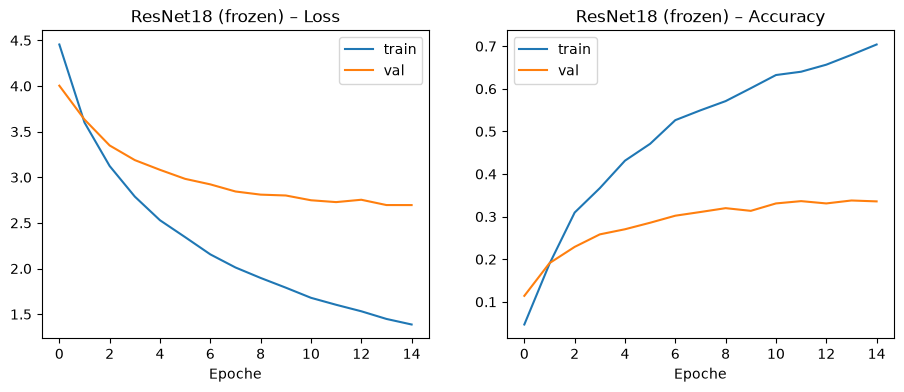

In [9]:
run_transfer("ResNet18", "frozen", epochs=15, lr_head=1e-3)

### 3.2 ResNet18 Fine-Tuning

ResNet18 (finetune): 11,227,812 von 11,227,812 Parametern trainierbar


[ 1] train loss 3.885 acc  13.3 % | val loss 2.730 acc  31.6 %


[ 2] train loss 1.960 acc  52.2 % | val loss 1.974 acc  46.1 %


[ 3] train loss 1.001 acc  78.1 % | val loss 1.645 acc  54.0 %


[ 4] train loss 0.483 acc  91.8 % | val loss 1.515 acc  58.2 %


...

[ 7] train loss 0.079 acc  99.2 % | val loss 1.403 acc  62.0 %


[ 8] train loss 0.039 acc  99.9 % | val loss 1.378 acc  62.7 %


[ 9] train loss 0.034 acc  99.7 % | val loss 1.385 acc  63.5 %


[10] train loss 0.020 acc  99.9 % | val loss 1.383 acc  63.0 %
Finished Training on cuda in 183.4 s


Test-Accuracy: 63.97 %  |  Trainingszeit: 183.4 s


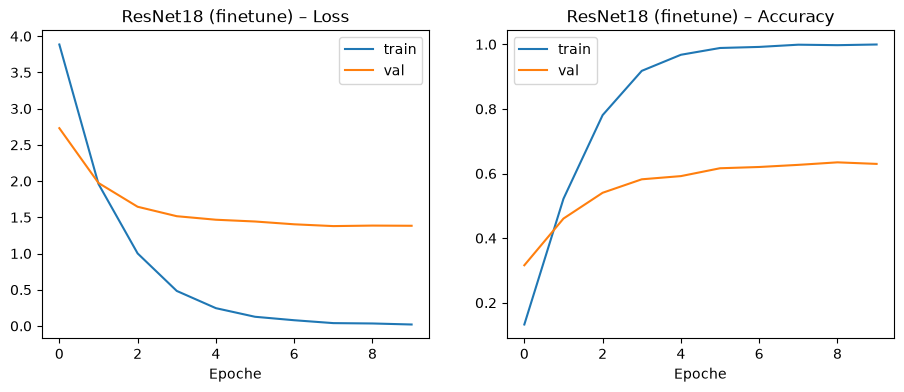

In [10]:
run_transfer("ResNet18", "finetune", epochs=10, lr_head=1e-3, lr_backbone=1e-4)

### 3.3 EfficientNet_B5 als Fixed Feature Extractor

EfficientNet_B5 (frozen): 204,900 von 28,545,684 Parametern trainierbar


[ 1] train loss 4.215 acc   7.9 % | val loss 3.785 acc  14.1 %


[ 2] train loss 3.514 acc  21.3 % | val loss 3.457 acc  23.0 %


[ 3] train loss 3.154 acc  29.9 % | val loss 3.224 acc  26.3 %


[ 4] train loss 2.883 acc  36.7 % | val loss 3.053 acc  26.9 %


...

[12] train loss 1.840 acc  60.3 % | val loss 2.427 acc  42.1 %


[13] train loss 1.770 acc  62.1 % | val loss 2.394 acc  42.4 %


[14] train loss 1.706 acc  62.3 % | val loss 2.329 acc  44.0 %


[15] train loss 1.653 acc  64.7 % | val loss 2.303 acc  43.8 %
Finished Training on cuda in 742.1 s


Test-Accuracy: 42.36 %  |  Trainingszeit: 742.1 s


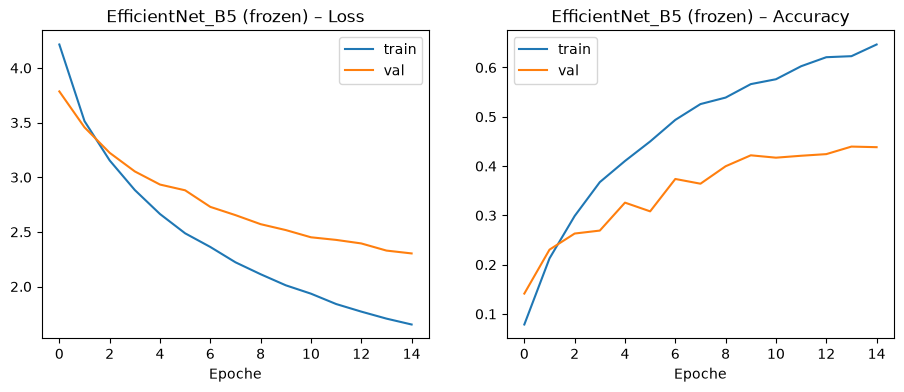

In [11]:
run_transfer("EfficientNet_B5", "frozen", epochs=15, lr_head=1e-3, batch_size=16)

### 3.4 EfficientNet_B5 Fine-Tuning

EfficientNet_B5 (finetune): 28,545,684 von 28,545,684 Parametern trainierbar


[ 1] train loss 3.561 acc  18.7 % | val loss 1.995 acc  44.3 %


[ 2] train loss 1.334 acc  63.8 % | val loss 1.142 acc  64.9 %


[ 3] train loss 0.552 acc  84.7 % | val loss 0.894 acc  72.4 %


[ 4] train loss 0.247 acc  94.2 % | val loss 0.819 acc  75.6 %


...

[ 7] train loss 0.075 acc  98.6 % | val loss 0.867 acc  77.2 %


[ 8] train loss 0.063 acc  98.7 % | val loss 0.863 acc  77.6 %


[ 9] train loss 0.037 acc  99.3 % | val loss 0.836 acc  78.7 %


[10] train loss 0.032 acc  99.4 % | val loss 0.910 acc  78.8 %
Finished Training on cuda in 1041.2 s


Test-Accuracy: 78.13 %  |  Trainingszeit: 1041.2 s


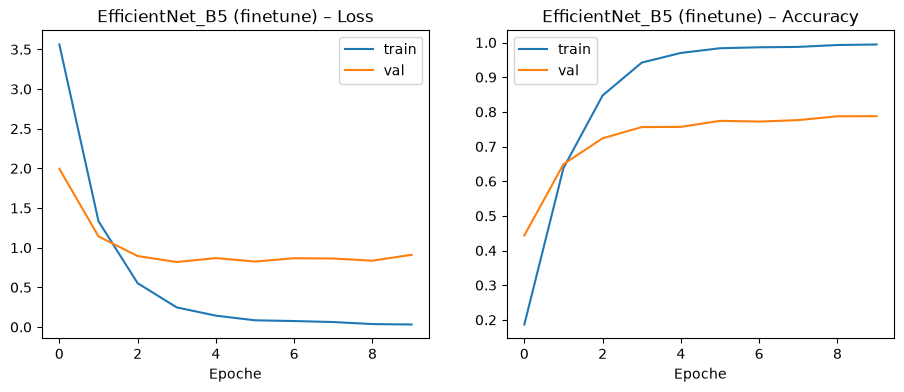

In [12]:
run_transfer("EfficientNet_B5", "finetune", epochs=10, lr_head=1e-3, lr_backbone=1e-4, batch_size=16)

## 4. Vergleich aller Ansätze

Alle Werte stammen aus demselben Test-Split (3333 Bilder), gemessen auf derselben GPU.

Modell,Strategie,Auflösung,Epochen,Trainierbare Parameter,Trainingszeit [s],Test-Accuracy [%],Zeit pro Epoche [s]
Custom CNN (BNNet),from scratch,64 px,20,"17,070,212",274.700000,7.320000,13.700000
ResNet18,fixed feature extractor,224 px,15,"51,300",279.800000,34.710000,18.700000
ResNet18,fine-tuning,224 px,10,"11,227,812",183.400000,63.970000,18.300000
EfficientNet_B5,fixed feature extractor,456 px,15,"204,900",742.100000,42.360000,49.500000
EfficientNet_B5,fine-tuning,456 px,10,"28,545,684",1041.200000,78.130000,104.100000


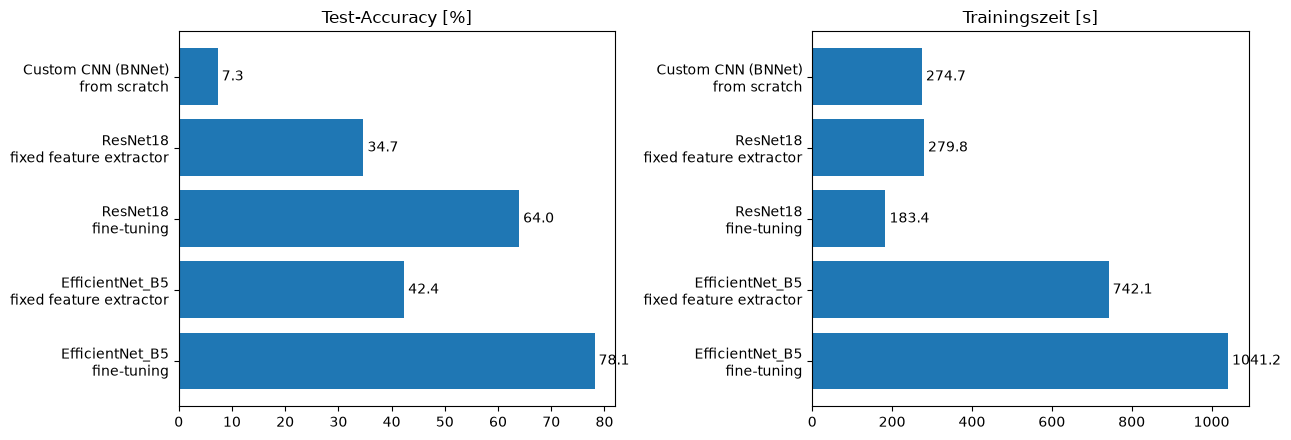

In [13]:
import pandas as pd

df = pd.DataFrame(results)
df["Zeit pro Epoche [s]"] = (df["Trainingszeit [s]"] / df["Epochen"]).round(1)
display(df.style.format({"Trainierbare Parameter": "{:,}", "Trainingszeit [s]": "{:.1f}",
                         "Test-Accuracy [%]": "{:.2f}", "Zeit pro Epoche [s]": "{:.1f}"}).hide(axis="index"))

labels = [f"{m}\n{s}" for m, s in zip(df["Modell"], df["Strategie"])]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.barh(labels, df["Test-Accuracy [%]"]); ax1.set(title="Test-Accuracy [%]"); ax1.invert_yaxis()
ax2.barh(labels, df["Trainingszeit [s]"]); ax2.set(title="Trainingszeit [s]"); ax2.invert_yaxis()
for ax, col in ((ax1, "Test-Accuracy [%]"), (ax2, "Trainingszeit [s]")):
    for i, v in enumerate(df[col]):
        ax.text(v, i, f" {v:.1f}", va="center")
plt.tight_layout()
plt.show()

## 5. Interpretation

| Modell | Strategie | Trainierbare Parameter | Trainingszeit | Test-Accuracy |
|---|---|---:|---:|---:|
| Custom CNN | from scratch (20 Ep., 64 px) | 17,07 M | 275 s | 7,3 % |
| ResNet18 | fixed feature extractor (15 Ep.) | 0,05 M | 280 s | 34,7 % |
| ResNet18 | fine-tuning (10 Ep.) | 11,23 M | 183 s | 64,0 % |
| EfficientNet_B5 | fixed feature extractor (15 Ep.) | 0,20 M | 742 s | 42,4 % |
| EfficientNet_B5 | fine-tuning (10 Ep.) | 28,55 M | 1041 s | **78,1 %** |

**Custom CNN:** Mit 7,3 % liegt die Baseline zwar deutlich über dem Zufallsniveau (1 %), ist für die Aufgabe aber praktisch unbrauchbar. Gründe:
- Pro Klasse gibt es nur ca. 33 Trainingsbilder. Damit lassen sich keine guten Features von Grund auf lernen.
- Bei 64×64 px gehen genau die Details verloren, an denen man Varianten unterscheidet (Triebwerke, Fensterreihen, Rumpflänge).
- Die Lernkurven steigen nach 20 Epochen noch an. Train- und Val-Accuracy liegen nahe beieinander, das Netz ist also eher *unter*- als übertrainiert. Mehr Epochen würden helfen, die Lücke zu den vortrainierten Netzen aber nicht schließen.
- Obwohl das CNN mehr trainierbare Parameter hat als ResNet18 (fast alle in `fc1`), schneidet es weit schlechter ab. Entscheidend sind die vortrainierten Features, nicht die Parameterzahl.

**Fixed Feature Extractor:** Nur der neue Kopf wird trainiert (51 k bzw. 205 k Parameter). Damit erreicht man schon das 5- bis 6-fache der Baseline. Mehr ist nicht drin, weil ImageNet zwar Klassen wie „airliner“ oder „warplane“ kennt, aber keine Flugzeugvarianten. Die eingefrorenen Features sind also nicht fein genug. Der lineare Kopf passt sich zudem stärker an die Trainingsdaten an (ResNet18: 70 % train vs. 34 % val).

**Fine-Tuning:** Hier lohnt sich Transfer Learning am meisten. Die Accuracy steigt gegenüber dem eingefrorenen Backbone um +29 (ResNet18) bzw. +36 Prozentpunkte (EfficientNet_B5), weil sich die Features an die feinen Unterschiede anpassen können. Die getrennten Lernraten (Backbone 1e-4, Kopf 1e-3) sorgen dafür, dass das Training stabil bleibt und die vortrainierten Gewichte nicht „zerstört“ werden. Allerdings ist das Overfitting deutlich: Die Train-Accuracy erreicht ~99 %, die Val-Accuracy flacht nach 6–8 Epochen ab, und bei EfficientNet_B5 steigt der Val-Loss ab Epoche 4 wieder leicht an. Mehr Epochen bringen also kaum etwas. Weiterhelfen würden stärkere Augmentation (z. B. `RandomResizedCrop`, Farb-Jitter), Early Stopping oder ein Learning-Rate-Scheduler.

**ResNet18 vs. EfficientNet_B5:** EfficientNet_B5 erreicht mit Fine-Tuning die beste Accuracy (78,1 %). Dafür braucht es aber ca. 5,7× so lange wie ResNet18 mit Fine-Tuning, 2,5× so viele Parameter, 456-px-Eingaben und ~11 GB GPU-Speicher (Batchgröße 16). Als Feature Extractor ist EfficientNet_B5 (742 s, 42 %) **sowohl langsamer als auch schlechter** als ResNet18 mit Fine-Tuning (183 s, 64 %).
→ Das beste Verhältnis aus Aufwand und Ergebnis bietet **ResNet18 mit Fine-Tuning**. EfficientNet_B5 mit Fine-Tuning lohnt sich nur, wenn die letzten ~14 Prozentpunkte den 5-fachen Rechenaufwand wert sind.

**Zur Trainingszeit:** Bei Custom CNN und ResNet18 begrenzt nicht die GPU die Geschwindigkeit, sondern das **Dekodieren der großen JPEGs** (bis 1600 px) im DataLoader. Deshalb dauert eine Epoche bei ResNet18 eingefroren und mit Fine-Tuning gleich lange (~18 s). Der eingefrorene Ansatz braucht insgesamt sogar länger, weil er 15 statt 10 Epochen läuft. Beim Feature Extractor ließen sich die Backbone-Features auch einmalig vorberechnen. Dann bestünde das Training nur noch aus einem linearen Klassifikator und wäre in Sekunden fertig. EfficientNet_B5 dagegen ist durch die GPU begrenzt.

**Einschränkungen des Vergleichs:** Split, Metrik, Hardware, Trainingsschleife und Zeitmessung sind für alle Ansätze gleich. Unterschiedlich sind die Epochenzahl (20 / 15 / 10), die Auflösung (jeweils die von den Gewichten vorgegebene) und die Batchgröße (16 bei EfficientNet_B5). Jede Konfiguration wurde nur einmal mit einem Seed trainiert, Unterschiede von wenigen Prozentpunkten sind daher nicht belastbar. Die großen Abstände (7 % → 35–42 % → 64–78 %) sind dagegen eindeutig.

**Fazit:** Auf einem kleinen, fein unterteilten Datensatz wie FGVC-Aircraft ist Transfer Learning dem Training von Grund auf klar überlegen. Fine-Tuning schlägt den Fixed Feature Extractor deutlich. Die beste Accuracy liefert EfficientNet_B5 mit Fine-Tuning, das beste Verhältnis aus Aufwand und Ergebnis ResNet18 mit Fine-Tuning.